In [21]:
#IMPORTS

import re
import csv
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from fitting_GUI import *
from collections import defaultdict

In [22]:
#DIRECTORIES

CALIBRATION_DIR = Path("Calibration")
MEASUREMENTS_DIR = Path("Metal measurements")

# folders = {"calibration": CALIBRATION_DIR, "measurements": MEASUREMENTS_DIR}
folders = {"measurements": MEASUREMENTS_DIR}
groups = ["Experiment", "Data", "Instruments"]

#CONSTANTS

CHANNEL_DIV = 8
A_CAL, B_CAL = 11.591, 9.0511 #energy (keV) = A_CAL * (channel / gain) + B_CAL

FWHM_TO_SIGMA = 2.3548

In [23]:
#LOADING DATA

def gain_from_name(stem):
    return int(re.search(r"(?:^|_)g_?(\d+)", stem).group(1)) #finds number after g


def convert_to_energy(data):
    for d in data.values():
        for e in d.values():
            e["energy"] = A_CAL * (e["channels"] / CHANNEL_DIV / e["gain"]) + B_CAL

data = {}
for name, folder in folders.items():
    data[name] = {}
    for f in sorted(folder.glob("*.nc")):
        if name == "calibration":
            key = f.stem
        else:
            parts = f.stem.split("_")
            key = f"week{parts[1]}_metal_{parts[3]}"

        if f in data[name]:
            print(f"Warning: key '{key}' already used in {name}, skipping {f.name}")
            continue
        if f.stat().st_size == 0:
            print(f"Warning: {f.name} is empty, skipping")
            continue
        else:
            print(f"Loading {f.name}, filesize: {f.stat().st_size}")
        
        with xr.open_dataset(f, group="Data", mask_and_scale=False) as ds:
            counts = ds["MCA"].values #(1, 8000), uint32
        spectrum = counts[0].astype(float) #float avoids uint32 wraparound
        channels = np.arange(len(spectrum))
        entry = {"counts": counts, "spectrum": spectrum, "channels": channels, "gain": gain_from_name(f.stem)}
        data[name][key] = entry

#CONVERSION

convert_to_energy(data)

Loading w_2_m_1_g_50_1.nc, filesize: 46531
Loading w_2_m_1_g_50_2.nc, filesize: 46531
Loading w_2_m_2_g_50.nc, filesize: 46531
Loading w_2_m_3_g_50.nc, filesize: 46531
Loading w_3_m_1_g_50.nc, filesize: 46531
Loading w_3_m_2_g_50.nc, filesize: 46531
Loading w_3_m_3_g_50.nc, filesize: 46531


In [24]:
#IDENTIFICATION TABLE

def load_table(path):
    table = defaultdict(list) #element -> [(line, energy, intensity), ...]
    with open(path, newline="") as fh:
        for r in csv.DictReader(fh):
            table[r["element"]].append((r["line"], float(r["energy"]), float(r["intensity"])))
    return table

def weighted_energy(lines, prefix):
    """Intensity-weighted mean energy of all lines starting with 'Ka' or 'Kb'."""
    pts = [(E, I) for name, E, I in lines if name.startswith(prefix)]
    return sum(E * I for E, I in pts) / sum(I for _, I in pts)

def identify(r, table, top=3):
    """r = results[folder][key]. Compares the two fitted peaks with each element."""
    peaks = [r["peak1"], r["peak2"]]
    if None in peaks:
        print("Need two successful fits")
        return
    a, b = sorted(peaks, key=lambda p: p["mu"]) #lower energy = Kalpha, higher = Kbeta
    sig_a, sig_b = a["fwhm"] / 2.3548, b["fwhm"] / 2.3548

    scores = []
    for el, lines in table.items():
        Ea, Eb = weighted_energy(lines, "Ka"), weighted_energy(lines, "Kb")
        chi2 = ((a["mu"] - Ea) / sig_a) ** 2 + ((b["mu"] - Eb) / sig_b) ** 2
        scores.append((chi2, el, Ea, Eb))

    print(f"measured: K\u03b1 {a['mu']:.2f} keV, K\u03b2 {b['mu']:.2f} keV")
    for chi2, el, Ea, Eb in sorted(scores)[:top]:
        print(f"  {el:>3}: K\u03b1 {Ea:.2f}, K\u03b2 {Eb:.2f}  (score {chi2:.2f})")

#GRAPH

def rank_elements(r, table):
    """r = results[folder][key]. Returns (a, b, scores) with a = lower-energy peak (Ka),
    b = higher-energy peak (Kb), and scores = sorted [(score, element, Ea, Eb), ...]."""
    peaks = [r["peak1"], r["peak2"]]
    if None in peaks:
        return None
    a, b = sorted(peaks, key=lambda p: p["mu"])
    sig_a, sig_b = a["fwhm"] / FWHM_TO_SIGMA, b["fwhm"] / FWHM_TO_SIGMA
    scores = []
    for el, lines in table.items():
        try:
            Ea, Eb = weighted_energy(lines, "Ka"), weighted_energy(lines, "Kb")
        except ZeroDivisionError: #element has no Ka or no Kb line
            continue
        chi2 = ((a["mu"] - Ea) / sig_a) ** 2 + ((b["mu"] - Eb) / sig_b) ** 2
        scores.append((chi2, el, Ea, Eb))
    return a, b, sorted(scores)

def show_identification(data, results, table, top=3, ncols=3, band="mu_err"):
    """One panel per measurement with two fitted peaks: spectrum, fitted peak positions
    (red = lower-energy peak, blue = higher-energy peak) with a shaded band, and the
    Ka (solid) / Kb (dashed) lines of the `top` closest elements.
    band = "mu_err" shades +-1 sigma uncertainty of the fitted position,
    band = "fwhm" shades the full width at half maximum of each peak."""
    items = []
    for name, d in results.items():
        for key, r in d.items():
            if key in data.get(name, {}):
                ranked = rank_elements(r, table)
                if ranked is not None:
                    items.append((name, key, ranked))
    if not items:
        print("No measurements with two successful fits")
        return

    colors = ["tab:green", "tab:orange", "tab:purple", "tab:brown", "tab:pink", "tab:olive", "tab:cyan"]

    for (name, key, (a, b, scores)) in items:
        e, sp = data[name][key]["energy"], data[name][key]["spectrum"]
        best = scores[:top]

        #x range: all measured peaks and all drawn lines, plus padding
        xs = [a["mu"], b["mu"]] + [E for _, _, Ea, Eb in best for E in (Ea, Eb)]
        pad = 3 * max(a["fwhm"], b["fwhm"])
        lo, hi = min(xs) - pad, max(xs) + pad
        mask = (e >= lo) & (e <= hi)
        plt.figure()
        plt.plot(e, sp, lw=0.8, color="gray")
        for p, c, nm in ((a, "red", "K\u03b1"), (b, "blue", "K\u03b2")):
            half = p["mu_err"] if band == "mu_err" else p["fwhm"] / 2
            plt.axvline(p["mu"], color=c, lw=1.5, label=f"fit {nm} {p['mu']:.2f} \u00b1 {half:.2f}")
            plt.axvspan(p["mu"] - half, p["mu"] + half, color=c, alpha=0.25, lw=0)
        for i, (chi2, el, Ea, Eb) in enumerate(best):
            c = colors[i % len(colors)]
            plt.axvline(Ea, color=c, ls="-", lw=1.2, label=f"{el} (score {chi2:.1f})")
            plt.axvline(Eb, color=c, ls="--", lw=1.2)

        plt.xlim(lo, hi)
        if mask.any():
            plt.ylim(0, sp[mask].max() * 1.1)
        plt.title(f"{name}/{key}\nmeasured: K\u03b1 {a['mu']:.2f}, K\u03b2 {b['mu']:.2f} keV", fontsize=8)
        plt.xlabel("Energy (keV)")
        plt.ylabel("Counts")
        plt.legend(fontsize=7, loc="upper left")

    plt.show()


measurements/week2_metal_1
Need two successful fits

measurements/week2_metal_2
Need two successful fits

measurements/week2_metal_3
measured: Kα 78.29 keV, Kβ 82.91 keV
   Pb: Kα 74.16, Kβ 85.27  (score 0.24)
   Bi: Kα 76.25, Kβ 87.69  (score 0.28)
   Tl: Kα 72.11, Kβ 82.90  (score 0.41)

measurements/week3_metal_1
measured: Kα 58.21 keV, Kβ 65.08 keV
   Ta: Kα 57.07, Kβ 65.48  (score 0.25)
    W: Kα 58.83, Kβ 67.51  (score 0.71)
   Re: Kα 60.62, Kβ 69.58  (score 3.26)

measurements/week3_metal_2
measured: Kα 66.04 keV, Kβ 74.57 keV
   Pt: Kα 66.20, Kβ 76.05  (score 0.24)
   Ir: Kα 64.30, Kβ 73.85  (score 0.54)
   Au: Kα 68.13, Kβ 78.29  (score 2.19)

measurements/week3_metal_3
measured: Kα 71.31 keV, Kβ 80.64 keV
   Hg: Kα 70.10, Kβ 80.57  (score 0.22)
   Tl: Kα 72.11, Kβ 82.90  (score 0.57)
   Au: Kα 68.13, Kβ 78.29  (score 2.06)


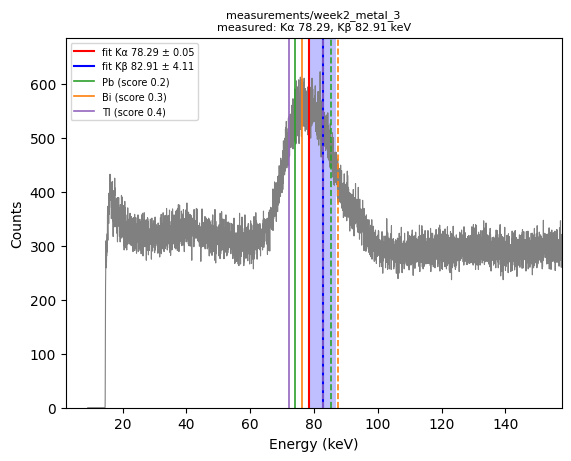

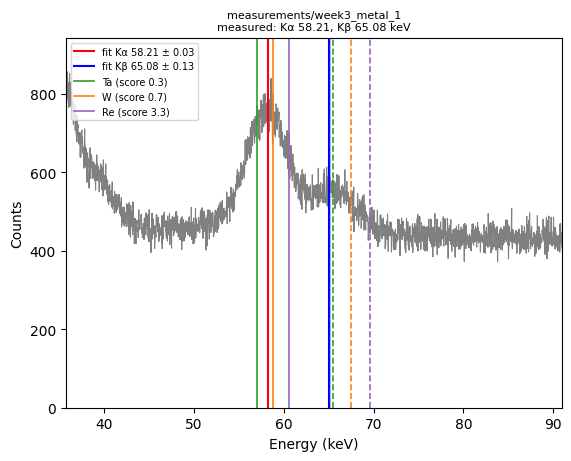

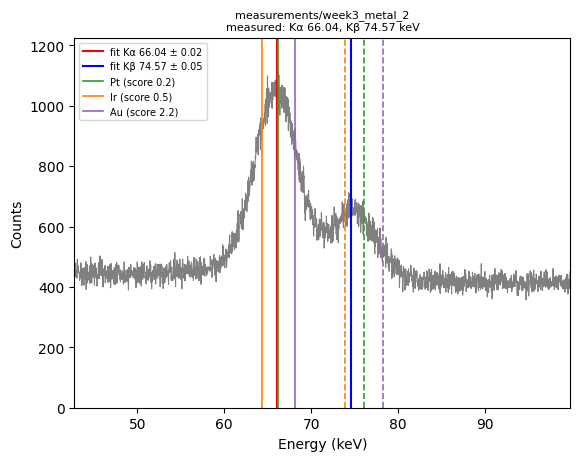

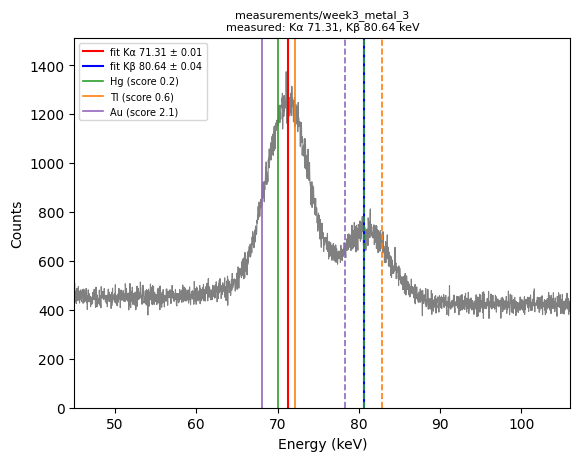

In [25]:
#rating is given by the difference in energy multiplied by the gauss width divided by the width at half height
#this means a deviation of 1 sigma gives a score of 1, and is at roughly 0.42 width at half height

results = load_results()

table = load_table("xray_energies.csv")

for folder, d in results.items():
    if folder == "calibration":
        continue
    for key, r in d.items():
        print(f"\n{folder}/{key}")
        identify(r, table)

show_identification(data, results, table, top=3)